# 7.2 Распределения и выбросы — код страницы

Аналитика 101 · блок «Дата аналитика» · тема 07 «Разведочный анализ» · страница 7.2.

В ноутбуке семь блоков кода со страницы. Четыре ячейки раздела «Код» идут подряд и пользуются общими переменными: describe с квантилями, гистограммы всех числовых столбцов, пики на круглых суммах, три правила выбросов. Три проверки из «Нюансов» самостоятельны: нули и логарифм, возраст 99, выброс по комбинации. Данные учебные: выгрузка клиентов из общего набора темы `data/eda/`.

**Как работать.** Выполняйте ячейки по порядку сверху вниз.

Вывод получен на Python 3.13, NumPy 2.5, pandas 3.0, SciPy 1.18 и matplotlib 3.10.

## Где лежат данные

Код страницы читает файл по пути от корня папки с материалами: `data/eda/clients_export.csv`. Ноутбук лежит в папке страницы, поэтому первая ячейка поднимается до папки, в которой есть `data/`, и делает её рабочей.

In [1]:
import os
import pathlib
import platform

import matplotlib
import numpy as np
import pandas as pd
import scipy

root = pathlib.Path.cwd()
while not (root / "data" / "eda").is_dir() and root != root.parent:
    root = root.parent                      # поднимаемся, пока рядом не окажется data/eda/
assert (root / "data" / "eda" / "clients_export.csv").exists(), \
    "Не найдена папка data/eda/. Скачайте общий набор темы 07 и положите data/ рядом с папкой страницы"
os.chdir(root)

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scipy 1.18.1 | matplotlib 3.10.0


## Код: от describe до трёх правил

Четыре ячейки выполняются по порядку: следующие пользуются таблицей `df` из первой.

### describe: траты от 0 до 19,9 млн, медиана в 2,5 раза ниже среднего

In [2]:
import numpy as np
import pandas as pd
from scipy import stats

df = pd.read_csv("data/eda/clients_export.csv")
num = df.select_dtypes("number").drop(columns="client_id")  # id — ярлык, а не величина
pct = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
print(num.describe(percentiles=pct).round(1).to_string())

s = df["spend_q1"]
print("\nусечённое среднее, по 10% с краёв:", round(stats.trim_mean(s, 0.1)))
print("MAD — медиана |x − медиана|:", stats.median_abs_deviation(s))

           age     tier  visits_q1  orders_q1    spend_q1
count  12040.0  12040.0    12040.0    12040.0     12040.0
mean      38.3      2.2        8.2        2.0     12379.2
std       14.8      1.2        3.3        1.5    259131.0
min       18.0      1.0        0.0       -1.0         0.0
1%        18.0      1.0        2.0       -1.0         0.0
5%        18.0      1.0        3.0        0.0         0.0
25%       29.0      1.0        6.0        1.0      2560.0
50%       37.0      2.0        8.0        2.0      5020.0
75%       44.0      3.0       10.0        3.0      9800.0
95%       59.0      5.0       14.0        5.0     25470.0
99%       99.0      5.0       18.0        6.0     52227.6
max       99.0      5.0       24.0       10.0  19931000.0

усечённое среднее, по 10% с краёв: 6080
MAD — медиана |x − медиана|: 3160.0


### Одна строка — пять гистограмм, и у трат вышел один столбик

age          18 … 99          пустых корзин:  7   в самой высокой:  10%
tier          1 … 5           пустых корзин: 25   в самой высокой:  40%
visits_q1     0 … 24          пустых корзин:  5   в самой высокой:  12%
orders_q1    -1 … 10          пустых корзин: 18   в самой высокой:  26%
spend_q1      0 … 19,931,000  пустых корзин: 24   в самой высокой: 100%


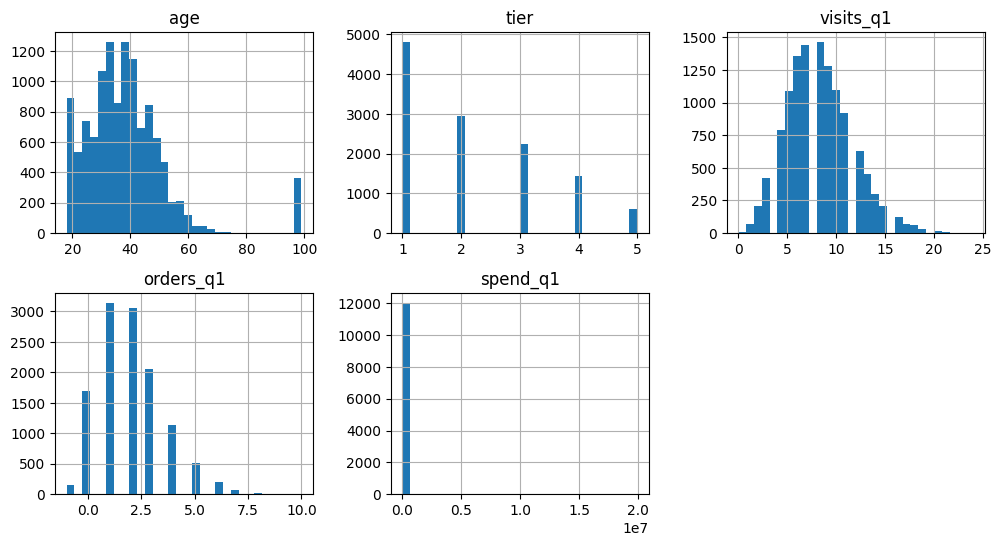

In [3]:
axes = num.hist(bins=30, figsize=(12, 6), layout=(2, 3))  # пять гистограмм одним вызовом

for ax in axes.flat[:num.shape[1]]:               # что нарисовано: высоты столбиков
    h = np.array([bar.get_height() for bar in ax.patches])
    lo = round(ax.patches[0].get_x(), 6) + 0.0   # + 0.0 убирает «−0»
    hi = ax.patches[-1].get_x() + ax.patches[-1].get_width()
    print(f"{ax.get_title():10} {lo:>4,.0f} … {hi:<11,.0f} пустых корзин: {(h == 0).sum():>2}"
          f"   в самой высокой: {h.max() / h.sum():>4.0%}")

### На 5 000 ₽ клиентов в 44 раза больше, чем на соседних суммах

In [4]:
pos = s[(s > 0) & (s < 1_000_000)]                # покупатели, без пяти ошибок ×1000
cnt = pos.value_counts().reindex(np.arange(10, 105_000, 10), fill_value=0)
near = (cnt.rolling(61, center=True, min_periods=1).sum() - cnt) / 60  # соседи ±300 ₽
ratio = (cnt / near).where((cnt.index % 500 == 0) & (cnt >= 10))  # круглые и не редкие

top = ratio.nlargest(4).index
print(pd.DataFrame({"клиентов": cnt[top], "у соседа": near[top].round(1),
                    "во сколько раз": ratio[top].round(1)}).to_string())
round1000 = pos % 1000 == 0
print(f"кратны 1 000: {round1000.mean():.1%} сумм, без 5 000 ₽: "
      f"{(round1000 & (pos != 5000)).mean():.1%} (случайно ждём около 1%)")

          клиентов  у соседа  во сколько раз
spend_q1                                    
5000           381       8.6            44.0
6500            13       6.5             2.0
6000            11       7.9             1.4
2500            15      12.0             1.2
кратны 1 000: 4.6% сумм, без 5 000 ₽: 0.9% (случайно ждём около 1%)


### Три правила — от 5 до 844 флагов на одном столбце

In [5]:
q1, q3 = s.quantile([0.25, 0.75])
mad = stats.median_abs_deviation(s)
bounds = {"IQR": q3 + 1.5 * (q3 - q1),              # правило Тьюки
          "z > 3": s.mean() + 3 * s.std(),           # три стандартных отклонения
          "MAD > 3,5": s.median() + 3.5 * mad / 0.6745}  # модифицированная z-оценка
err = s > 1_000_000                                  # пять ошибок ×1000 с логарифмической шкалы

rows = {rule: {"граница, ₽": round(b), "флагов": (s > b).sum(),
               "из 5 ошибок": (s[err] > b).sum()} for rule, b in bounds.items()}
print(pd.DataFrame(rows).T.to_string())

clean = s[~err]                                      # без ошибок маскировка уходит
z_bound = clean.mean() + 3 * clean.std()
print(f"\nz > 3 без ошибок: граница {z_bound:,.0f} ₽, флагов {(clean > z_bound).sum()}")
both = (s > bounds["IQR"]) & (s > bounds["MAD > 3,5"])
print("общих флагов у IQR и MAD:", both.sum(), "из", (s > bounds["IQR"]).sum())

           граница, ₽  флагов  из 5 ошибок
IQR             20660     844            5
z > 3          789772       5            5
MAD > 3,5       21417     795            5

z > 3 без ошибок: граница 37,329 ₽, флагов 298
общих флагов у IQR и MAD: 795 из 844


## Нюансы

В первой ячейке NumPy дважды предупреждает о делении на ноль внутри логарифма — так и задумано. В ноутбуке предупреждения стоят под выводом ячейки, а на странице — между его строками, там, где они возникли.

### Нули — клиенты без заказов, и логарифм их не берёт

In [6]:
import numpy as np
import pandas as pd

df = pd.read_csv("data/eda/clients_export.csv")
s = df["spend_q1"]
zero = s == 0
print(f"нулей: {zero.sum()} из {len(s)} ({zero.mean():.1%})")
print("заказов у них:", df.loc[zero, "orders_q1"].value_counts().to_dict())
print("медиана: все", s.median(), "| купившие", s[~zero].median())

first = s.head(4).to_numpy()                  # 0, 0, 0 и 9 710 ₽
print(np.log10(first))
print(np.log1p(first).round(2))               # log(1 + x): ноль остаётся нулём
print(np.log1p(df["orders_q1"].to_numpy()).min())  # но −1 заказ из 7.1 даёт −inf

нулей: 1717 из 12040 (14.3%)
заказов у них: {0.0: 1690, -1.0: 27}
медиана: все 5020.0 | купившие 6060.0
[      -inf       -inf       -inf 3.98721923]
[0.   0.   0.   9.18]
-inf


/tmp/ipykernel_2879/350808954.py:12: RuntimeWarning: divide by zero encountered in log10
  print(np.log10(first))
/tmp/ipykernel_2879/350808954.py:14: RuntimeWarning: divide by zero encountered in log1p
  print(np.log1p(df["orders_q1"].to_numpy()).min())  # но −1 заказ из 7.1 даёт −inf


Строки RuntimeWarning — предупреждения NumPy о делении на ноль внутри логарифма. В Jupyter они такие же, только с другим именем файла.

### 99 — не возраст, а код «не указан»: в пропуск, строку оставить

In [7]:
import pandas as pd

df = pd.read_csv("data/eda/clients_export.csv")
age = df["age"]
vc = age.value_counts().sort_index()
print(vc.iloc[[0, 1, 2, -3, -2, -1]].to_string())   # края: 18, 19, 20 … 74, 75, 99
print(f"среднее {age.mean():.1f}, без 99 — {age[age != 99].mean():.1f}")

df["age_missing"] = age == 99              # 99 — код «не указан», то есть пропуск
df["age"] = age.mask(df["age_missing"])    # 99 → NaN, строка и другие столбцы остаются
print("пропусков:", df["age"].isna().sum(), "| медиана:", df["age"].median())

age
18.0    627
19.0    125
20.0    138
74.0      3
75.0      2
99.0    360
среднее 38.3, без 99 — 36.4
пропусков: 360 | медиана: 36.0


### 1 000 ₽ без единого заказа: по отдельности всё нормально

In [8]:
import pandas as pd

df = pd.read_csv("data/eda/clients_export.csv")
d = df[df["spend_q1"] < 1_000_000]                   # пять ошибок ×1000 уже нашли


def iqr_out(x):                                      # флаг по одной переменной
    q1, q3 = x.quantile([0.25, 0.75])
    return (x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))


odd = d[(d["orders_q1"] == 0) & (d["spend_q1"] > 0)]  # траты без единого заказа
print(odd[["client_id", "visits_q1", "orders_q1", "spend_q1"]].to_string(index=False))
print("флаг по spend_q1:", iqr_out(d["spend_q1"])[odd.index].any(),
      "| по orders_q1:", iqr_out(d["orders_q1"])[odd.index].any())
print("заказы есть, трат нет:", ((d["orders_q1"] > 0) & (d["spend_q1"] == 0)).sum())

per = d["spend_q1"] / d["orders_q1"].where(d["orders_q1"] > 0)  # траты на один заказ
print(f"на заказ: медиана {per.median():,.0f} ₽, дороже 20 000 ₽ — {(per > 20_000).sum()} клиента")

 client_id  visits_q1  orders_q1  spend_q1
  101263.0          5        0.0    1000.0
флаг по spend_q1: False | по orders_q1: False
заказы есть, трат нет: 0
на заказ: медиана 2,983 ₽, дороже 20 000 ₽ — 202 клиента
